# Imports and preprocess data

In [1]:
import numpy as np 
from pathlib import Path
import sys, os
import matplotlib.pyplot as plt
sys.path.append(os.path.join(os.getcwd(), '..'))

from utils.eda_helpers import clean_data
from utils.eda_helpers import read_csv_numeric

import importlib
import utils.decision_tree, utils.random_forest, utils.cv
importlib.reload(utils.decision_tree)
importlib.reload(utils.random_forest)
importlib.reload(utils.cv)
from utils.decision_tree import Decision_Tree
from utils.random_forest import Random_Forest
from utils.cv import compute_roc_auc, compute_training_error

In [2]:
file_path = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_FOLDER = os.path.join(file_path, '..', 'dataset')
x_indices, x_data = read_csv_numeric(os.path.join(DATA_FOLDER, "x_train.csv"))
y_indices, y_data = read_csv_numeric(os.path.join(DATA_FOLDER, "y_train.csv"))

In [3]:
del x_indices["Id"]
del y_indices["Id"]
x_data = clean_data(x_data, x_indices)

In [4]:
columns_to_train_extended = [
    "VETERAN3", "STOPSMK2", "BLIND", "WTKG3", "CHCCOPD1", "EDUCA", "_SMOKER3", 
    "CHKHEMO3", "METVL11_", "_LMTSCL1", "SEX", "_RFSEAT2", "_ASTHMS1", "_PASTRNG",
      "TOLDHI2", "CVDSTRK3", "LMTJOIN3", "_DRNKWEK", "FLUSHOT6", "_FRUITEX",
        "PA1VIGM_", "CHILDREN", "BEANDAY_", "EXERANY2", "AVEDRNK2", "_BMI5", 
        "MAXVO2_", "MARITAL", "PAMIN21_", "_VEGETEX", "CHOLCHK", "HIVTST6", 
        "_AGE80", "USEEQUIP", "DROCDY3_", "FEETCHK", "ORNGDAY_", "PAMIN11_", 
        "_MINAC21", "PAFREQ2_", "_CASTHM1", "METVL21_", "DRADVISE", "BPMEDS", 
        "_FRUTSUM", "MEDCOST", "VEGEDA1_", "PREDIAB1", "GENHLTH", "PERSDOC2", 
        "_RFHLTH", "CHCOCNCR", "_RACE_G1", "DIFFALON", "_CRACE1", "FLSHTMY2", 
        "PADUR2_", "EMPLOY1", "INCOME2", "USENOW3", "_PASTAE1", "PAFREQ1_", 
        "WTCHSALT", "DRNKANY5", "CHCSCNCR", "SXORIENT", "GRENDAY_", "MENTHLTH", 
        "MAXDRNKS", "CHCKIDNY", "PAVIG11_", "DRNK3GE5", "_TOTINDA", "MSCODE", 
        "ADDEPEV2", "QLACTLM2", "PNEUVAC3", "SMOKDAY2", "_AIDTST3", "_PAREC1", 
        "EXRACT21", "_LMTWRK1", "_LMTACT1", "STRFREQ_", "DIFFDRES", "_MRACE1", 
        "TRNSGNDR", "DIABETE3", "INSULIN", "DECIDE", "FEETCHK2", "HAVARTH3", 
        "DIABAGE2", "DOCTDIAB", "PA1MIN_", "_MINAC11", "EXRACT11", "_PACAT1", 
        "LONGWTCH", "_MISVEGN", "CHECKUP1", "DIFFWALK", "PHYSHLTH", "FRUTDA1_", 
        "FRUIT1", "SMOKE100", "PAVIG21_", "ARTHSOCL", "_PAINDX1", "PAMISS1_", 
        "BLOODCHO", "HTM4", "ALCDAY5", "RENTHOM1", "_MISFRTN", "SCNTWRK1", 
        "POORHLTH", "PADUR1_", "FC60_", "_VEGESUM", "BPHIGH4"]


# this is the one we should use for training
final_feature_set = ['_CASTHM1', 'FLUSHOT6', 'METVL11_', '_PASTRNG', 'EDUCA', 'CHCCOPD1', 'DRADVISE', 
                     'CHCKIDNY', 'ARTHSOCL', 'MENTHLTH', 'SMOKE100', 'DOCTDIAB', 'DIABAGE2', 'VETERAN3', 
                     'CHKHEMO3', 'SEX', '_DRNKWEK', 'JOINPAIN', 'MARITAL', 'EXERANY2', '_PACAT1', 'INSULIN', 
                     'DIFFALON', 'FRUIT1', 'QLACTLM2', 'BLIND', 'PADUR2_', 'PAFREQ2_', 'LMTJOIN3', 'CHOLCHK', 
                     'POORHLTH', 'DIABETE3', '_FRUTSUM', 'PERSDOC2', 'EXRACT21', 'FEETCHK', '_VEGESUM', 'PNEUVAC3', 
                     'BPHIGH4', 'GENHLTH', 'EXRACT11', '_BMI5', 'DECIDE', '_ASTHMS1', '_MRACE1', '_LMTSCL1', 'ORNGDAY_', 
                     'MSCODE', 'PHYSHLTH', 'TOLDHI2', 'PADUR1_', 'DIFFWALK', 'BEANDAY_', 'CHCSCNCR', 'PAFREQ1_', '_AIDTST3', 
                     'FLSHTMY2', 'PA1VIGM_', 'METVL21_', 'SXORIENT', 'ARTHDIS2', 'PA1MIN_', 'MAXVO2_', '_RACE_G1', 'LONGWTCH', 
                     'SCNTWRK1', 'FEETCHK2', 'EMPLOY1', 'BLOODCHO', 'USENOW3', 'DRNKANY5', '_PAREC1', 'DIFFDRES', 'USEEQUIP', 
                     'ADDEPEV2', '_AGE80', 'HTM4', 'INCOME2', 'CVDSTRK3', 'CHCOCNCR', 'MEDCOST', 'PREDIAB1', 'BPMEDS', 'HAVARTH3', 
                     'CHECKUP1', 'TRNSGNDR', 'CHILDREN']


In [5]:
len(final_feature_set)

87

In [6]:
x_train = x_data.copy()
col_means = np.nanmean(x_train, axis=0)
inds = np.where(np.isnan(x_train))
x_train[inds] = np.round(np.take(col_means, inds[1])).astype(int)
x_train

array([[0.00000e+00, 5.30000e+01, 1.10000e+01, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00],
       [1.00000e+00, 3.30000e+01, 1.20000e+01, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00],
       [2.00000e+00, 2.00000e+01, 1.00000e+01, ..., 1.00000e+00,
        2.00000e+00, 2.00000e+00],
       ...,
       [3.28132e+05, 3.90000e+01, 1.00000e+01, ..., 2.00000e+00,
        2.00000e+00, 2.00000e+00],
       [3.28133e+05, 3.30000e+01, 1.20000e+01, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00],
       [3.28134e+05, 3.20000e+01, 9.00000e+00, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00]], shape=(328135, 322))

In [7]:
y_data[y_data[:, -1] == -1, -1] = 0
y_data[:, -1].sum()

np.float64(28975.0)

# Train DT

[Progress] Split calls: 5
[Progress] Split calls: 10
[Progress] Split calls: 15
[Progress] Split calls: 20
[Progress] Split calls: 25
[Progress] Split calls: 30
[Progress] Split calls: 35
[Progress] Split calls: 40
[Progress] Split calls: 45
[Progress] Split calls: 50
[Progress] Split calls: 55
[Progress] Split calls: 60


Train accuracy: 0.9129900803023145


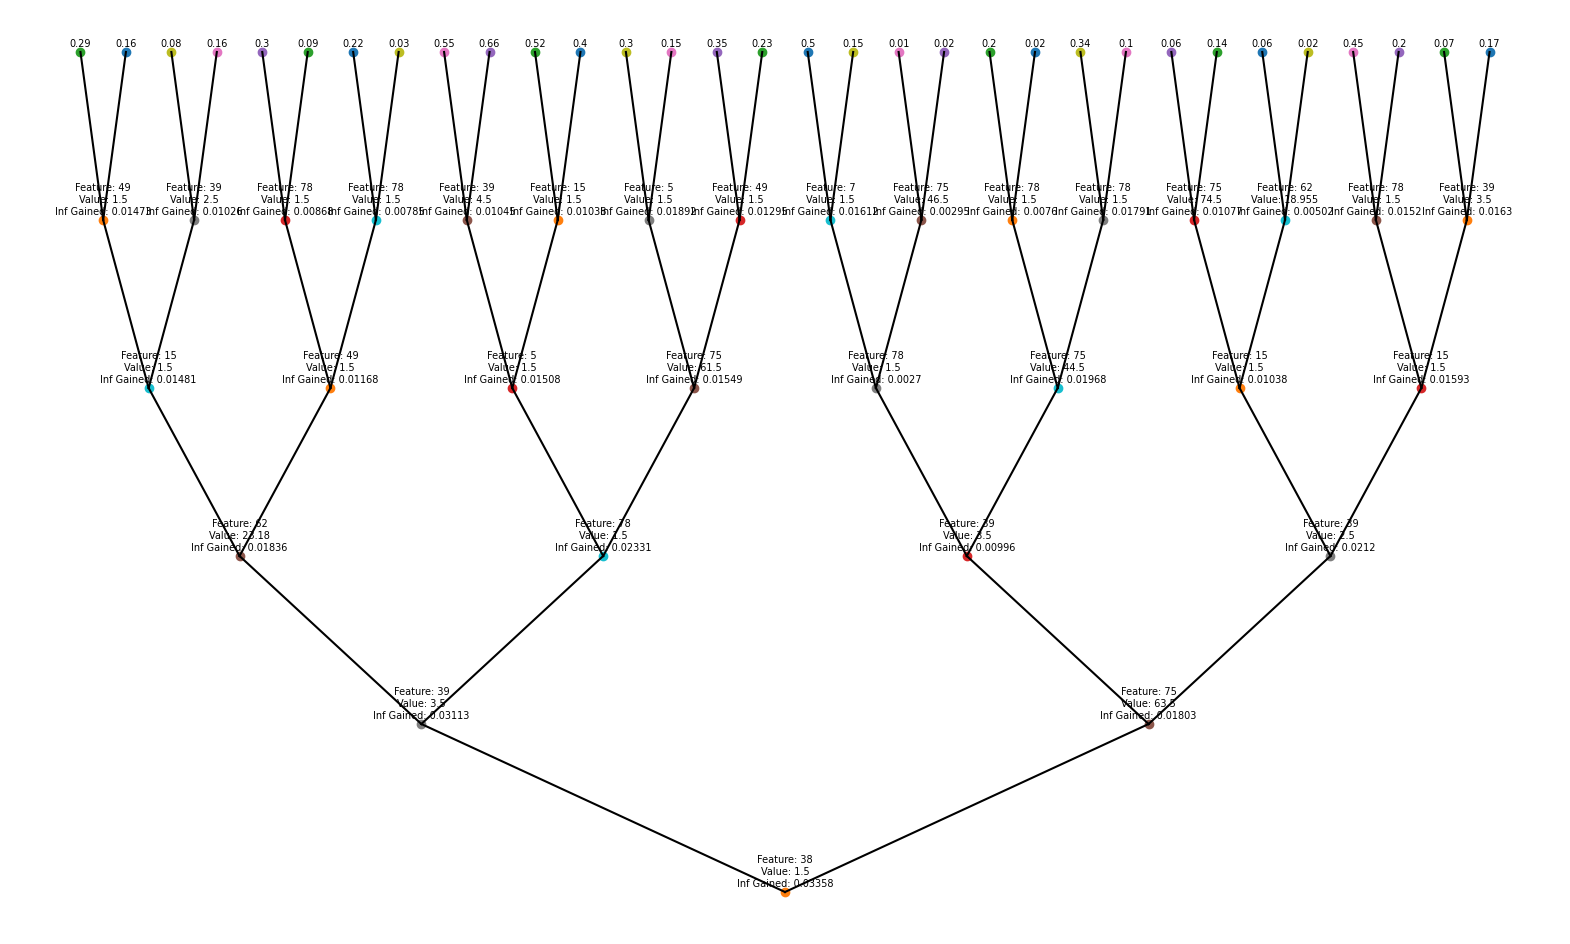

In [8]:
selected_indices = [x_indices[col] for col in final_feature_set if col in x_indices]
x_selected = x_train[:, selected_indices]

dt = Decision_Tree(maximum_depth=6, 
                   minimum_leaves=3, 
                   splitting_criterion="entropy", stopping_criterion=0.0,
                   show_split_progress=True)
dt.train(x_selected, y_data[:, 1])
preds = dt.predict(x_selected)
print("Train accuracy:", np.mean(preds == y_data[:, 1]))
dt.print_tree()

In [9]:
y_true = y_data[:, 1].astype(int)     # or y_data[:, -1]
y_pred = preds.astype(int)
y_proba = dt.predict_proba(x_selected)

In [10]:
# --- Compute metrics manually ---
tp = np.sum((y_pred == 1) & (y_true == 1))
tn = np.sum((y_pred == 0) & (y_true == 0))
fp = np.sum((y_pred == 1) & (y_true == 0))
fn = np.sum((y_pred == 0) & (y_true == 1))

In [11]:
accuracy  = (tp + tn) / (tp + tn + fp + fn + 1e-10)
precision = tp / (tp + fp + 1e-10)
recall    = tp / (tp + fn + 1e-10)
f1        = 2 * precision * recall / (precision + recall + 1e-10)
roc_auc   = compute_roc_auc(y_true, y_proba)

In [12]:

# Print metrics
print("\n=== Decision Tree Evaluation Metrics ===")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {roc_auc:.4f}")


=== Decision Tree Evaluation Metrics ===
Accuracy : 0.9130
Precision: 0.5669
Recall   : 0.0620
F1 Score : 0.1118
ROC AUC  : 0.1811


In [13]:
# --- Confusion matrix -----
conf_matrix = np.array([[tn, fp],
                        [fn, tp]])

print("\nConfusion Matrix:")
print(conf_matrix)


Confusion Matrix:
[[297788   1372]
 [ 27179   1796]]


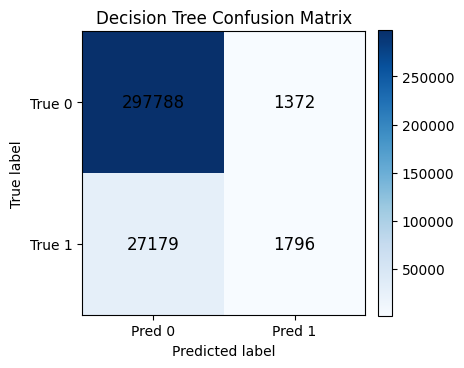

In [14]:
# --- Plot confusion matrix ---
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(conf_matrix, cmap="Blues")

# Tick labels
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Pred 0", "Pred 1"])
ax.set_yticklabels(["True 0", "True 1"])

# Annotate cells
for i in range(2):
    for j in range(2):
        ax.text(j, i, conf_matrix[i, j], ha="center", va="center", color="black", fontsize=12)

ax.set_title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.show()

# Train RF

In [28]:
selected_indices = [x_indices[col] for col in final_feature_set if col in x_indices]
x_selected = x_train[:, selected_indices]

rf = Random_Forest(base_learners_num=20, max_tree_depth=7, min_samples_leaf=1, 
                   min_information_gain=0, split_feature_ratio=0.25, splits_by_feature=2,
                   show_split_progress=False, split_row_ratio=0.5)

rf.train(x_selected, y_data[:, 1])
preds = rf.predict(x_selected)
print("Train accuracy:", np.mean(preds == y_data[:, 1]))
for learner in rf.base_learners:
    learner.print_tree()

MemoryError: Unable to allocate 218. MiB for an array with shape (87, 328135) and data type float64

# Cross validation

In [ ]:
def cross_validate(
    model_fn,
    X,
    y,
    k_folds=5,
    seed=None,
    sampling_fn=None,
    sampling_kwargs=None,
    model_kwargs=None,
    predict_fn=None,
    train_fn=None,
    metric_fn=None,
    thresholds=None,
    use_predictions=False,
    verbose=True,
):
    """
    General-purpose k-fold cross-validation with optional sampling,
    flexible argument control, and multi-threshold evaluation.

    Args:
        model_fn (callable): Function or class used to train a model.
                             Should return trained model or weights.
        X (np.ndarray): Feature matrix (n_samples, n_features)
        y (np.ndarray): Label vector (n_samples,)
        k_folds (int): Number of folds for cross-validation.
        seed (int, optional): Random seed for reproducibility.
        sampling_fn (callable, optional): Sampling function (undersample, oversample, smote...).
        sampling_kwargs (dict, optional): Arguments for the sampling function.
        model_kwargs (dict, optional): Arguments for the model training function.
        predict_fn (callable, optional): Function to generate predictions.
                                         Must return (y_pred, y_proba) for logistic-like models.
        metric_fn (callable, optional): Function computing metrics.
        thresholds (float or list, optional): Threshold(s) for prediction evaluation.
        use_predictions (bool): If True, metric_fn expects (y_true, y_pred, y_proba)
                                instead of (y_true, X_val, model).
        verbose (bool): Whether to print per-fold metrics.

    Returns:
        dict: Averaged metrics across folds. (or across folds × thresholds)
    """
    rng = np.random.default_rng(seed)
    y = y.reshape(-1, 1)
    n = len(y)

    # shuffle indices,  create folds
    indices = rng.permutation(n)
    folds = np.array_split(indices, k_folds)
    all_metrics = []

    # ensure thresholds is iterable
    if thresholds is not None and not isinstance(thresholds, (list, np.ndarray)):
        thresholds = [thresholds]

    for i, val_idx in enumerate(folds):
        train_idx = np.setdiff1d(indices, val_idx)
        X_train, y_train = X[train_idx], y[train_idx]
        X_val, y_val = X[val_idx], y[val_idx]

        # optional sampling on training data only
        if sampling_fn is not None:
            kwargs = sampling_kwargs or {}
            try:
                X_train, y_train = sampling_fn(X_train, y_train, **kwargs)
            except Exception as e:
                print(f"[Warning] Sampling failed in fold {i+1}: {e}")
                continue

        # train model (note y, X order)
        model_args = model_kwargs or {}
        model = model_fn(**model_args)
        
        if train_fn is None:
            model.train(X_train, y_train)
        else:
            train_fn(X_train, y_train)
        w = model[0] if isinstance(model, tuple) else model

        if predict_fn is None:
            raise ValueError("predict_fn must be provided for evaluation.")
        if metric_fn is None:
            raise ValueError("metric_fn must be provided for evaluation.")

        # evaluate at one or multiple thresholds
        if thresholds is not None:
            for thr in thresholds:
                y_pred, y_proba = predict_fn(X_val, w)
                metrics = metric_fn(y_val, X_val, w, threshold=thr, returning="all")
                metrics["threshold"] = thr
                all_metrics.append(metrics)
                if verbose:
                    print(f"Fold {i+1}/{k_folds} @ thr={thr:.2f} → " +
                          ", ".join([f"{k}:{v:.3f}" for k, v in metrics.items() if k != "threshold"]))
        else:
            y_pred, y_proba = predict_fn(X_val, w)
            metrics = metric_fn(y_val, X_val, w, returning="all")
            all_metrics.append(metrics)
            if verbose:
                msg = f"Fold {i+1}/{k_folds} → " + ", ".join([f"{k}:{v:.3f}" for k, v in metrics.items()])
                print(msg)

    if not all_metrics:
        raise ValueError("No successful folds. Check your sampling or training function.")

    # avg metrics
    if thresholds is not None:
        avg_metrics = {}
        for t in thresholds:
            subset = [m for m in all_metrics if abs(m["threshold"] - t) < 1e-9]
            avg_metrics[t] = {k: np.mean([m[k] for m in subset])
                              for k in subset[0] if k not in ["threshold"]}
        return avg_metrics
    else:
        avg_metrics = {m: np.mean([fold[m] for fold in all_metrics]) for m in all_metrics[0]}
        return avg_metrics

In [ ]:
# Running it with Cross Validation
selected_indices = [x_indices[col] for col in columns_to_train_extended if col in x_indices]
x_selected = x_train[:, selected_indices]
cross_validate(x_selected, y_data[:, 1], model_fn=Decision_Tree, k_folds=5,
               model_kwargs={"maximum_depth":10, "minimum_leaves":7, "splitting_criterion":"entropy",
                             "min_information_gain":0, "splits_by_feature":5,
                             "show_split_progress":True},
               predict_fn=Decision_Tree.predict,
               metric_fn=compute_roc_auc)  # Replace None with your metric function

MemoryError: Unable to allocate 303. MiB for an array with shape (121, 328135) and data type float64